## PageRank y HITS: HITS

- HITS sobre el bipartito dirigido entidad → proveedor: **hubs = entidades**, **authorities = proveedores**

- Validación con SVD, concentración del puntaje y comparación con PageRank

- Local: A es de 2,992 × 86,017 con 136k entradas no nulas; la iteración y `svds` tardan segundos

### Constantes

- `RANGO_PESO`: pesos que se comparan en HITS

In [1]:
RANGO_PESO = ["binario", "n_adj", "log_monto"]

### Utilidades

In [2]:
%cd /home/jovyan/work/04_PAGERANKHITS

/home/jovyan/work/04_PAGERANKHITS


In [3]:
NOTEBOOK = "c_hits"
%run ../funciones.ipynb
%run funciones.ipynb

In [4]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [5]:
config = leer_config()
n_e, n_p = config["n_e"], config["n_p"]
v = pd.read_parquet(datos_dir / "nodos.parquet").merge(pd.read_parquet(datos_dir / "pagerank.parquet")[["idx", "pr"]], on="idx")
v["pct_pr"] = pct_por_tipo(v, "pr")
a = pd.read_parquet(datos_dir / "aristas.parquet")
A = matriz_bip(a, n_e, n_p, PESO)
print(f"A: {A.shape[0]:,} × {A.shape[1]:,} | {A.nnz:,} entradas | peso = {PESO}")

A: 2,992 × 86,038 | 136,132 entradas | peso = n_adj


---
### **1. HITS**

- **authority** a = Aᵀh: un proveedor es autoridad si le compran buenos hubs

- **hub** h = A·a: una entidad es hub si compra a buenas autoridades

- h y a convergen al **primer par de vectores singulares** de A, a razón (σ₂/σ₁)²; se valida con `svds`

In [6]:
t0 = time.time()
h, au, k_h, err_h = hits_local(A)
seg_h = time.time() - t0
U, S, Vt = svds(A.astype(float), k=2)
o = np.argsort(-S)
s1, s2 = S[o]
u1, v1 = np.abs(U[:, o[0]]), np.abs(Vt[o[0]])
convergencia = pd.DataFrame([{"iteraciones": k_h, "seg": round(seg_h, 2), "sigma1": s1, "sigma2": s2,
                              "razon_conv": (s2 / s1) ** 2, "coseno_hubs_u1": h @ u1, "coseno_auth_v1": au @ v1}])
convergencia

,iteraciones,seg,sigma1,sigma2,razon_conv,coseno_hubs_u1,coseno_auth_v1
0,102,0.23,291.621884,258.674151,0.786803,1.0,1.0


- **Converge en XX iteraciones:** la razón (σ₂/σ₁)² = **XX** fija la velocidad

- **Coseno ≈ 1** con los vectores singulares: HITS es la SVD de rango 1 de la matriz entidad × proveedor (el mismo objeto que la Parte VI usa como embedding)

---
### **2. Concentración**

In [7]:
v["hits"] = np.r_[h, au]
v["pct_hits"] = pct_por_tipo(v, "hits")
filas = []
for t, rol in (("entidad", "hub"), ("proveedor", "authority")):
    s_ = v[v.tipo == t]
    for metodo, x in ((f"HITS ({rol})", s_.hits.to_numpy()), ("PageRank", s_.pr.to_numpy())):
        filas.append({"tipo": t, "metodo": metodo, "pct_nodos_con_puntaje": 100 * (x / x.max() > 1e-6).mean(),
                      "pct_puntaje_en_gigante": 100 * x[s_.en_gigante.to_numpy() == 1].sum() / x.sum(),
                      "cuota_top1pct": cuota_top(x), "gini": gini(x)})
concentracion = pd.DataFrame(filas).round(3)
concentracion

,tipo,metodo,pct_nodos_con_puntaje,pct_puntaje_en_gigante,cuota_top1pct,gini
0,entidad,HITS (hub),60.160,100.000,0.642,0.963
1,entidad,PageRank,100.000,98.974,0.177,0.647
2,proveedor,HITS (authority),62.381,100.000,0.734,0.979
3,proveedor,PageRank,100.000,99.034,0.137,0.360


- **Efecto de comunidad densa** (*tightly-knit community*):
  - Solo el **XX%** de los proveedores tiene authority distinta de 0
  - El **XX%** del puntaje queda en la componente gigante, y dentro de ella en su núcleo denso

- **PageRank reparte más** (Gini **XX** vs **XX**): el teletransporte da masa a todas las componentes

- **Lectura:** HITS mide pertenencia al **núcleo nacional** de compras; no ve los mercados locales

---
### **3. Hubs y authorities**

In [8]:
cols = ["nombre", "region", "grado", "fuerza", "monto", "hits", "pct_hits", "pct_pr"]
top_hubs = v[v.tipo == "entidad"].nlargest(15, "hits")[cols]
top_auth = v[v.tipo == "proveedor"].nlargest(15, "hits")[cols + ["es_consorcio"]]
display(top_hubs); display(top_auth)

,nombre,region,grado,fuerza,monto,hits,pct_hits,pct_pr
2190,SEGURO SOCIAL DE SALUD,LIMA,1918,5059.0,7.503673e+09,0.847814,1.000000,0.999666
1616,CENTRO NACIONAL DE ABASTECIMIENTO DE RECURSOS ESTRATEGICOS EN SALUD,LIMA,336,1660.0,4.828172e+09,0.455377,0.999666,0.992313
1758,INSTITUTO NACIONAL DE SALUD DEL NIÑO - SAN BORJA,LIMA,174,409.0,2.278276e+08,0.084235,0.999332,0.931818
72,INSTITUTO NACIONAL DE ENFERMEDADES NEOPLASICAS,LIMA,223,468.0,4.825732e+08,0.075493,0.998997,0.948864
1783,IAFAS DEL EJERCITO DEL PERU (FOSPEME),LIMA,192,535.0,2.286542e+08,0.074854,0.998663,0.958556
1402,DIRECCIÓN DE SANIDAD DE LA PNP,LIMA,259,588.0,4.324242e+08,0.071937,0.998329,0.966912
104,EJERCITO PERUANO,LIMA,1170,3647.0,1.855708e+09,0.067573,0.997995,0.999332
1390,GOBIERNO REGIONAL DE AYACUCHO - HOSPITAL HUAMANGA,AYACUCHO,154,348.0,1.105293e+08,0.058307,0.997660,0.929479
76,INSTITUTO NACIONAL DE SALUD DEL NIÑO,LIMA,203,356.0,2.023872e+08,0.055695,0.997326,0.930147
1922,HOSPITAL DE EMERGENCIAS VILLA EL SALVADOR,LIMA,155,289.0,1.586755e+08,0.051895,0.996992,0.891043


,nombre,region,grado,fuerza,monto,hits,pct_hits,pct_pr,es_consorcio
68219,DIAGNOSTICA PERUANA S.A.C.,None,109,572.0,4.083834e+08,0.259310,1.000000,0.999988,0.0
63267,CARDIO PERFUSION E.I.R.LTDA,None,29,163.0,1.129581e+08,0.248659,0.999988,0.999338,0.0
64253,LABORATORIOS AC FARMA S.A.,None,51,261.0,3.710908e+08,0.244560,0.999977,0.999744,0.0
62995,INSTITUTO QUIMIOTERAPICO S A,None,38,201.0,3.491083e+08,0.236071,0.999965,0.999512,0.0
63862,LABORATORIOS AMERICANOS S.A.,None,3,106.0,4.329240e+08,0.193825,0.999954,0.998082,0.0
68394,W.P. BIOMED SOCIEDAD ANONIMA,None,45,205.0,6.151969e+07,0.186862,0.999942,0.999605,0.0
63909,CYMED MEDICAL SAC,None,36,148.0,1.380560e+08,0.180844,0.999930,0.999233,0.0
64205,LINDE PERU S.R.L.,None,55,201.0,9.432611e+07,0.168971,0.999919,0.999628,0.0
62892,MEDIFARMA S A,None,47,143.0,6.364148e+08,0.168230,0.999907,0.999070,0.0
68270,COVIDIEN PERU S.A.,None,28,112.0,5.121185e+07,0.168149,0.999895,0.998663,0.0


- **Hubs:** **XX**; grandes compradoras con muchos proveedores en común con otras grandes

- **Authorities:** **XX**; proveedores de alcance nacional (insumos médicos, maquinaria, seguros, telecomunicaciones)

- **Ningún consorcio** en el top: venden a una sola entidad y quedan fuera del núcleo

---
### **4. Peso de las aristas**

In [9]:
hits_peso = {p: hits_local(matriz_bip(a, n_e, n_p, p)) for p in RANGO_PESO}
filas = []
for p, (hp, ap, kp, _) in hits_peso.items():
    for t, x, ref in (("entidad", hp, h), ("proveedor", ap, au)):
        m_ = v.loc[v.tipo == t, "monto"].to_numpy()
        filas.append({"peso": p, "tipo": t, "iteraciones": kp, "spearman_vs_elegido": spearman(x, ref),
                      "top20_vs_elegido": top_jaccard(x, ref), "spearman_monto": spearman(x, m_), "top20_vs_monto": top_jaccard(x, m_)})
peso_hits = pd.DataFrame(filas).round(3)
peso_hits

,peso,tipo,iteraciones,spearman_vs_elegido,top20_vs_elegido,spearman_monto,top20_vs_monto
0,binario,entidad,66,0.978,0.600,0.607,0.111
1,binario,proveedor,66,0.955,0.290,0.100,0.026
2,n_adj,entidad,102,1.000,1.000,0.547,0.081
3,n_adj,proveedor,102,1.000,1.000,0.100,0.026
4,log_monto,entidad,52,0.977,0.667,0.613,0.081
5,log_monto,proveedor,52,0.951,0.333,0.160,0.000


- Con `binario` y `log_monto` el top-20 de authorities coincide en **XX** con `n_adj`: el núcleo es el mismo con cualquier peso razonable

- Se mantiene `n_adj` por coherencia con PageRank

---
### **5. HITS vs PageRank**

In [10]:
filas = []
for t in ("entidad", "proveedor"):
    s_ = v[v.tipo == t]; gi = s_.en_gigante == 1
    filas.append({"tipo": t, "spearman": spearman(s_.hits, s_.pr), "spearman_en_gigante": spearman(s_.hits[gi], s_.pr[gi]),
                  "top20_jaccard": top_jaccard(s_.hits, s_.pr)})
hits_vs_pr = pd.DataFrame(filas).round(3)

p_ = v[v.tipo == "proveedor"].copy()
p_["alto_pr"], p_["alto_hits"] = p_.pct_pr >= P_ALTO, p_.pct_hits >= P_ALTO
cuadrantes = p_.groupby(["alto_pr", "alto_hits"]).size().reset_index(name="proveedores")
cc = ["nombre", "grado", "fuerza", "monto", "pct_pr", "pct_hits", "cuota_billetera", "es_consorcio"]
solo_pr = p_[p_.alto_pr & ~p_.alto_hits].nlargest(10, "pr")[cc]
solo_hits = p_[~p_.alto_pr & p_.alto_hits].nlargest(10, "hits")[cc]
display(hits_vs_pr); display(cuadrantes.pivot(index="alto_pr", columns="alto_hits", values="proveedores"))
display(solo_pr); display(solo_hits)

,tipo,spearman,spearman_en_gigante,top20_jaccard
0,entidad,0.598,0.558,0.053
1,proveedor,-0.141,-0.130,0.026


alto_hits,False,True
alto_pr,,
False,84514,663
True,663,198


,nombre,grado,fuerza,monto,pct_pr,pct_hits,cuota_billetera,es_consorcio
72095,TMI-TYC SOCIEDAD ANONIMA CERRADA - TMI-TYC S.A.C.,160,325.0,5.076491e+07,0.999965,0.975395,5.514560,0.0
70595,AGROINDUSTRIA LA PERLA DEL HUASCARAN S.R.L.,68,179.0,3.130010e+07,0.999954,0.813780,6.988340,0.0
62897,FERREYROS SOCIEDAD ANÓNIMA,171,236.0,5.844381e+08,0.999930,0.970966,4.322106,0.0
62896,UNIMAQ S.A.,166,209.0,2.048934e+08,0.999907,0.971292,8.473298,0.0
63145,IPESA S.A.C.,127,210.0,4.572544e+08,0.999895,0.972024,4.748701,0.0
76217,NEGOCIOS INNOVACIONES E INGENIERIA S.A.,65,175.0,2.853138e+08,0.999861,0.938748,1.724595,0.0
66608,CORPORACION DE LOS ANDES E.I.R.L.,78,128.0,2.348107e+07,0.999849,0.804052,5.053589,0.0
71649,FACOIMPEC E.I.R.L.,72,130.0,3.470480e+07,0.999837,0.852507,3.239833,0.0
69079,CORPORACION DE DISTRIBUCIONES Y SERVICIOS DEL NORTE S.A.C.,57,135.0,3.181943e+07,0.999826,0.893222,3.767785,0.0
57649,TRUYENQUE MALPARTIDA CESAR,24,204.0,4.108867e+07,0.999802,0.967782,1.724078,0.0


,nombre,grado,fuerza,monto,pct_pr,pct_hits,cuota_billetera,es_consorcio
76124,MASTER WORLD MEDICAL SOCIEDAD ANONIMA CERRADA,6,29.0,7431932.03,0.989168,0.999558,0.039124,0.0
68229,DIVCOM S.A.C.,8,32.0,11115135.70,0.989807,0.999547,0.057432,0.0
64906,SERVICIOS GENERALES MASA S.R.L.,3,25.0,13710112.59,0.986215,0.999523,0.052771,0.0
71673,STEFANO & MASA S.A.C.,7,24.0,5805866.00,0.985158,0.999442,0.163398,0.0
68527,ALEPH GROUP & ASOCIADOS SAC,4,23.0,3425654.90,0.982775,0.999407,0.024165,0.0
69655,PHARMACEUTICAL DISTOLOZA S.A.,11,36.0,16116688.76,0.989330,0.999384,0.078759,0.0
85776,J&J PRODUCTOS MEDICOS & FARMACEUTICOS DEL PERU S.A.,5,21.0,28301687.38,0.978893,0.999338,0.014336,0.0
68334,FARMACHIF S.R.L.,9,30.0,59236241.43,0.986239,0.999326,0.048461,0.0
71192,FJ NEGOCIOS INTEGRADOS S.A.C.,3,17.0,44520498.00,0.975918,0.999245,0.011351,0.0
81100,PANADEX PERU E.I.R.L.,5,21.0,22208894.94,0.980485,0.999175,0.054280,0.0


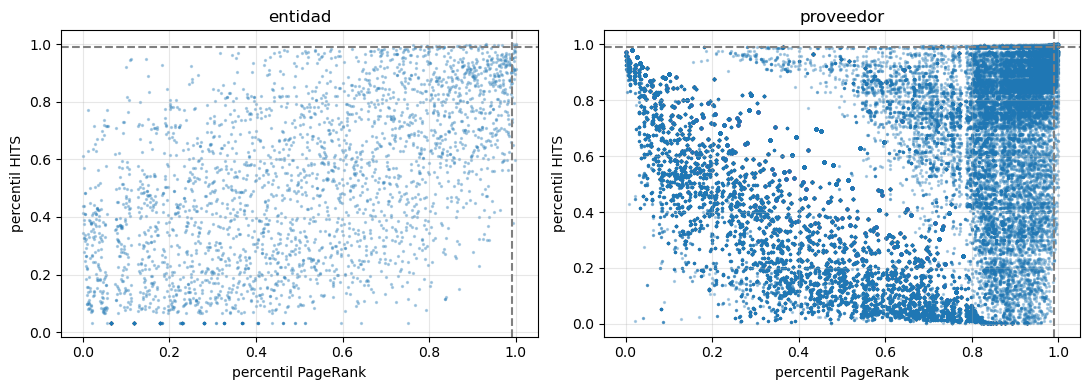

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k_, t in enumerate(("entidad", "proveedor")):
    s_ = v[v.tipo == t]
    ax[k_].scatter(s_.pct_pr, s_.pct_hits, s=2, alpha=.3)
    ax[k_].axvline(P_ALTO, ls="--", c="gray"); ax[k_].axhline(P_ALTO, ls="--", c="gray")
    ax[k_].set(xlabel="percentil PageRank", ylabel="percentil HITS", title=t)
mostrar_fig("hits_vs_pagerank")

- **Coinciden en el núcleo:** top-20 Jaccard **XX**; los grandes multicliente son centrales para ambos

- **Divergen fuera de él:**
  - **PageRank alto, HITS bajo** (**XX** proveedores): concentran la compra de entidades chicas o aisladas; su `cuota_billetera` es alta → **centralidad local**
  - **HITS alto, PageRank no tan alto** (**XX**): venden a varias grandes compradoras pero son una fracción pequeña de su gasto

- **Lectura:** PageRank (con teletransporte y pesos normalizados por comprador) capta **dependencia local**; HITS capta **pertenencia al núcleo**. Para PQ1 se usan juntos

---
### **6. Escritura de resultados**

In [12]:
pd.DataFrame({"idx": v.idx, "hits": v.hits}).to_parquet(datos_dir / "hits.parquet", index=False)
escritos = guardar_tablas({"hits_convergencia": convergencia, "concentracion": concentracion, "top_hubs": top_hubs,
                           "top_authorities": top_auth, "peso_hits": peso_hits, "hits_vs_pagerank": hits_vs_pr,
                           "cuadrantes": cuadrantes, "solo_pagerank_alto": solo_pr, "solo_hits_alto": solo_hits})

Escrito en 04_PAGERANKHITS/temp/c_hits/: hits_convergencia, concentracion, top_hubs, top_authorities, peso_hits, hits_vs_pagerank, cuadrantes, solo_pagerank_alto, solo_hits_alto


#### a. Verificación

In [13]:
verificar_salidas(escritos)
assert convergencia.coseno_hubs_u1[0] > 0.999 and convergencia.coseno_auth_v1[0] > 0.999, "HITS no coincide con la SVD"
print("HITS = primer par singular de A")

OK: 9 tablas (parquet + json) | 1 figuras: hits_vs_pagerank
HITS = primer par singular de A


---
### **7. Cerrar sesión**

In [14]:
spark.stop()